In [44]:
# In this notebook we plot the output from Code 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import plot_utils as pltutils

In [55]:
def read_SEDsyn_cuts(filename='./../Code/SEDsyn_cuts_ord.dat'):
    fname = filename
    #fname format: Esy, Lsy*Esy, Labssy, l
    data = np.loadtxt(fname).transpose()
    Ns = int( np.max(data[3]) )
    NSED_sy = np.size(data[3]) // Ns
    print(f'{Ns=}, {NSED_sy=}')
    
    Esy = data[0][:NSED_sy]
    Lsy = np.zeros((Ns, NSED_sy))
    for i in range(Ns):
        Lsy[i] = data[2][i*NSED_sy:(i+1)*NSED_sy] / data[0][:NSED_sy]
    
    return Esy, Lsy, Ns, NSED_sy

In [77]:
eV = 1.60218e-12
pc = 3.086e+18

# Read zmin and zmax from the trajectory
traj = np.loadtxt('./../Code/trajectory.dat')
zmin = np.min(traj[:,0])
zmax = np.max(traj[:,0])

# Read the synchrotron SED at each cut (segment) along the jet; file already sorted in Esy
# Ns and NSED are the number of segments and of energy points, respectively
Esy, Lsy, Ns, NSED = read_SEDsyn_cuts()

# Read a file containing E, L1, L2, ..., Ltot (L1, ... are integrated up to certain heights)
synsed_output = np.loadtxt('./../Code/SEDsyn_jet.dat')
Lsy_tot_abs = synsed_output[:,-1]
Lsy_tot_unabs = synsed_output[:,-2]

Ns=60, NSED_sy=150


/tmp/ipykernel_15169/1220024639.py:15: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z ~ [\mathrm{cm}]$')


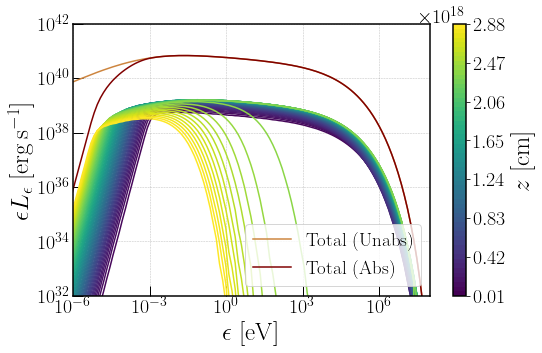

In [92]:
# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot total SED
ax.loglog(Esy, Lsy_tot_unabs, label='Total (Unabs)', color=colors[0])
ax.loglog(Esy, Lsy_tot_abs, label='Total (Abs)', color=colors[1])

# Plot individual curves for different Z

colormap, sm = pltutils.color_from_cmap('viridis',Ns, vmin=int(zmin), vmax=int(zmax))
for i in range(Ns):
    ax.loglog(Esy,Esy*Lsy[i], color=colormap[i])

plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z ~ [\mathrm{cm}]$')
# Set limits#
ax.set_ylim([1e32,1e42])
ax.set_xlim([1e-6,1e8])

# Legends and labels
plt.legend(loc='lower right', fontsize=19)
ax.set_xlabel('$\epsilon ~ [\mathrm{eV}]$')
ax.set_ylabel('$\epsilon L_{\epsilon} ~ [\mathrm{erg\,s^{-1}}]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)
pltutils.luc_std_plot(ax)

plt.show()



/tmp/ipykernel_15169/2201279001.py:39: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z(\\rm cm)$')


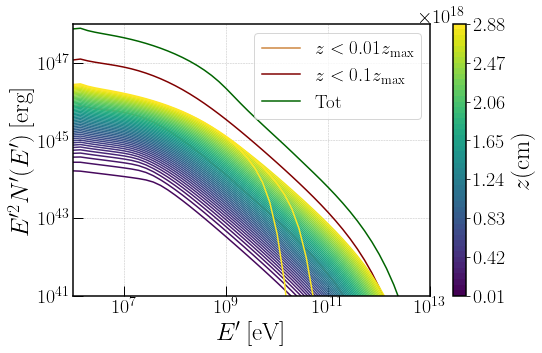

In [106]:
# # N(E) distribution

# Read the output of the jet model
NE_output = np.loadtxt('./../Code/NE_jet.dat')
NE_output_ord = np.loadtxt('./../Code/NE_cuts_ord.dat')

# Define quantities for total N
Ee  = NE_output[:,0]
z1  = NE_output[:,1]
z2  = NE_output[:,2]
tot = NE_output[:,3]

# Define quantities for N cuts
Eecut = NE_output_ord[:,0]
necut = NE_output_ord[:,1]

# take dimensions from array
n = int( np.max(NE_output_ord[:,2]) )
m = int( len(NE_output_ord[:,2]) / n )
# reshape arrays
Eecut = np.reshape(nucut,(n,m))
necut = np.reshape(necut,(n,m))

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot total SED
ax.loglog(nu,z1, label='$z< 0.01 z_{\\rm max}$', color=colors[0])
ax.loglog(nu,z2, label='$z< 0.1 z_{\\rm max}$', color=colors[1])
ax.loglog(nu,tot, label='Tot', color=colors[2])

# Plot individual curves for different Z

colormap, sm = pltutils.color_from_cmap('viridis', m, vmin=zmin, vmax=zmax)
for i in range(m):
    ax.loglog(Eecut[i]/eV,necut[i]*nucut[i]**2, color=colormap[i])

plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z(\\rm cm)$')
# Set limits#
ax.set_ylim([1e41,1e48])
ax.set_xlim([1e6,1e13])

# Legends and labels
plt.legend(loc='upper right', fontsize=19)
ax.set_xlabel('$E\' \: [\\rm eV]$')
ax.set_ylabel('$E\'^2 N \' (E\') \: [\\rm erg]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)
plt.show()